# Formal tests: simulated vs empirical citation distributions

This notebook runs the tests proposed in `email.md` on the shortlisted stage-2 settings: the
8 settings closest in shape to the empirical distribution, with 3 seeds each.

* **Empirical target:** citations each paper receives from other papers in the corpus
  (`internal_citations`).
* **Null model:** a discrete power law, with `x_min` and `alpha_0` estimated **once** from the
  empirical data and treated as true. Citation counts are integers with many ties, so every test
  uses the discrete law.
* **Tests per run:**
  1. **A-D (fully specified):** discrete Anderson-Darling against `PL(alpha_0, x_min)`, with a Monte
     Carlo null.
  2. **LR:** `alpha = alpha_0` against a freely estimated `alpha`, compared with chi²(1).
  3. **Vuong:** power law vs log-normal on the tail; R < 0 favours the log-normal.
  4. **Two-sample A-D:** the simulated tail against the empirical tail directly, with no model
     assumed; permutation p-value.
* **Multiple testing:** Benjamini-Hochberg across the 24 runs, separately for each test.
* **Effect sizes:** reported next to the p-values. Tails of thousands of papers make every test
  sensitive to very small deviations.

In [1]:
import sys; sys.path.insert(0, "..")   # repo root, so `citesim` imports
import json, ast, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import powerlaw
from citesim.simulate import SimConfig
from citesim.gof import DiscretePowerLaw, ad_test, dpl_mle, lr_test, vuong_test, two_sample_ad
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
BASE = Path("../data/processed/citesim")
N_MC = 999
emp = np.load(BASE / "corpus.npz")["internal_citations"].astype(np.int64)
print(f"{len(emp):,} papers, {emp.sum():,} internal citations, {np.mean(emp == 0):.1%} never cited")

850,406 papers, 4,189,863 internal citations, 36.3% never cited


## 1. Empirical tail: `x_min`, `alpha_0`

In [2]:
fit = powerlaw.Fit(emp[emp > 0], discrete=True, verbose=False, parameter_ranges={"alpha": [1, 10]})
XMIN = int(fit.xmin)
emp_tail = emp[emp >= XMIN]
ALPHA0, ALPHA0_SE = dpl_mle(emp_tail, XMIN)
null = DiscretePowerLaw(ALPHA0, XMIN, cap=100_000)
ad_self = ad_test(emp_tail, null, n_mc=N_MC)
v_emp = vuong_test(emp, XMIN)
print(f"x_min = {XMIN}, alpha_0 = {ALPHA0:.4f} ± {ALPHA0_SE:.4f}, n_tail = {len(emp_tail):,} ({len(emp_tail)/len(emp):.2%} of papers)")
print(f"empirical tail vs its own fit: A² = {ad_self[0]:.3f}, p = {ad_self[1]:.3f} (optimistic: parameters fitted on the same data)")
print(f"empirical Vuong PL vs LN: R = {v_emp['vuong_R']:.2f}, p = {v_emp['p_vuong']:.3f}")

x_min = 88, alpha_0 = 2.7846 ± 0.0289, n_tail = 3,814 (0.45% of papers)
empirical tail vs its own fit: A² = 0.190, p = 0.990 (optimistic: parameters fitted on the same data)
empirical Vuong PL vs LN: R = -0.83, p = 0.406


## 2. Calibration of the Monte Carlo A-D test
This checks the rejection rate under H0 at the empirical tail size. It should be close to the nominal level.

In [3]:
rng = np.random.default_rng(123)
cal = np.array([ad_test(null.sample(len(emp_tail), rng), null, n_mc=199, seed=s)[1] for s in range(100)])
print(f"rejection rate at 5%: {np.mean(cal < 0.05):.2f}; at 10%: {np.mean(cal < 0.10):.2f} (100 replicates)")

rejection rate at 5%: 0.08; at 10%: 0.14 (100 replicates)


## 3. Shortlisted runs

In [4]:
def configs(path):
    out = []
    for b in json.loads(Path(path).read_text()):
        for seed in b["seed"]:
            out.append(SimConfig(weights=tuple(b["weights"][0]), citation_signal=b["citation_signal"][0],
                                 page_size=b["page_size"][0], per_page=tuple(b["per_page"][0]), seed=seed))
    return out

runs = [(m, c) for m in (500, 2000) for c in configs(f"../configs/grid_shortlist_m{m}.json")]
missing = [c.run_id for m, c in runs if not (BASE / f"titles_m{m}_n850406_all_s0/runs" / c.run_id / "counts.npy").exists()]
assert not missing, missing
print(len(runs), "runs")

24 runs


In [5]:
def ccdf(x, grid):
    xs = np.sort(x)
    return 1 - np.searchsorted(xs, grid, side="left") / len(xs)

GRID = np.unique(np.round(np.logspace(0, 4, 80)).astype(int))
EMP_CCDF = ccdf(emp, GRID)
rows = []
for m, c in runs:
    x = np.load(BASE / f"titles_m{m}_n850406_all_s0/runs" / c.run_id / "counts.npy").astype(np.int64)
    tail = x[x >= XMIN]
    a2, p_ad = ad_test(tail, null, n_mc=N_MC, seed=c.seed)
    a2s, p_2s = two_sample_ad(tail, emp_tail, seed=c.seed)
    rows.append(dict(top_m=m, signal=c.citation_signal, page=c.page_size, per_page=str(list(c.per_page)),
                     w=str(list(c.weights)), seed=c.seed, never_cited=np.mean(x == 0), max=int(x.max()),
                     n_tail=len(tail), A2=a2, p_AD=p_ad, **lr_test(tail, ALPHA0, XMIN), **vuong_test(x, XMIN),
                     A2_2s=a2s, p_2s=p_2s, ks_shape=float(np.max(np.abs(ccdf(x, GRID) - EMP_CCDF)))))
res = pd.DataFrame(rows)

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty_like(q); out[o] = np.minimum(q, 1); return out

for col in ["p_AD", "p_LR", "p_vuong", "p_2s"]:
    res["q" + col[1:]] = bh(res[col])
res["delta_alpha"] = res.alpha_hat - ALPHA0
res.round(4).to_csv(BASE / "formal_tests_runs.csv", index=False)
res[["top_m", "signal", "page", "per_page", "w", "seed", "never_cited", "max", "n_tail", "A2", "q_AD",
     "alpha_hat", "delta_alpha", "q_LR", "vuong_R", "q_vuong", "q_2s", "ks_shape"]].round(4)

,top_m,signal,page,per_page,w,seed,never_cited,max,n_tail,A2,q_AD,alpha_hat,delta_alpha,q_LR,vuong_R,q_vuong,q_2s,ks_shape
0,500,static,20,"[3, 1, 1]","[0.5, 0.0, 0.4, 0.1]",0,0.3484,488,3680,373.2895,0.001,4.1722,1.3875,0.0,-6.3090,0.0,0.0011,0.0143
1,500,static,20,"[3, 1, 1]","[0.5, 0.0, 0.4, 0.1]",1,0.3491,454,3713,375.5026,0.001,4.1745,1.3899,0.0,-6.5496,0.0,0.0011,0.0137
2,500,static,20,"[3, 1, 1]","[0.5, 0.0, 0.4, 0.1]",2,0.3487,460,3711,375.4521,0.001,4.1716,1.3870,0.0,-6.3632,0.0,0.0011,0.0141
3,500,dynamic,20,[5],"[0.6, 0.0, 0.3, 0.1]",0,0.3482,610,4795,80.6772,0.001,3.3003,0.5157,0.0,-9.5337,0.0,0.0011,0.0145
4,500,dynamic,20,[5],"[0.6, 0.0, 0.3, 0.1]",1,0.3488,655,4848,89.7148,0.001,3.3256,0.5409,0.0,-9.5496,0.0,0.0011,0.0140
5,500,dynamic,20,[5],"[0.6, 0.0, 0.3, 0.1]",2,0.3489,648,4909,89.9230,0.001,3.3227,0.5380,0.0,-10.0315,0.0,0.0011,0.0138
6,500,dynamic,10,[5],"[0.65, 0.0, 0.35, 0.0]",0,0.3451,909,5106,30.4720,0.001,3.0291,0.2444,0.0,-10.8028,0.0,0.0011,0.0177
7,500,dynamic,10,[5],"[0.65, 0.0, 0.35, 0.0]",1,0.3438,939,5069,28.7781,0.001,3.0300,0.2454,0.0,-10.3521,0.0,0.0011,0.0190
8,500,dynamic,10,[5],"[0.65, 0.0, 0.35, 0.0]",2,0.3447,828,5072,28.4432,0.001,3.0368,0.2521,0.0,-9.9914,0.0,0.0011,0.0180
9,500,dynamic,10,[5],"[0.6, 0.0, 0.3, 0.1]",0,0.3521,997,5326,22.0157,0.001,2.9987,0.2141,0.0,-9.8098,0.0,0.0011,0.0187


## 4. Summary per setting (3 seeds)

In [6]:
key = ["top_m", "signal", "page", "per_page", "w"]
summary = res.groupby(key).agg(
    never_cited=("never_cited", "mean"), max=("max", "mean"), n_tail=("n_tail", "mean"),
    alpha_hat=("alpha_hat", "mean"), delta_alpha=("delta_alpha", "mean"),
    AD_reject=("q_AD", lambda q: f"{(q < 0.05).sum()}/3"), LR_reject=("q_LR", lambda q: f"{(q < 0.05).sum()}/3"),
    vuong_R=("vuong_R", "mean"), LN_favoured=("q_vuong", lambda q: f"{(q < 0.05).sum()}/3"),
    twosample_reject=("q_2s", lambda q: f"{(q < 0.05).sum()}/3"), ks_shape=("ks_shape", "mean"),
).sort_values("ks_shape")
summary.to_csv(BASE / "formal_tests_summary.csv")
summary.round(3)

never_cited       max    n_tail  alpha_hat  delta_alpha AD_reject LR_reject  vuong_R LN_favoured twosample_reject  ks_shape
top_m signal  page per_page        w                                                                                                                                                  
500   static  20   [3, 1, 1]       [0.5, 0.0, 0.4, 0.1]          0.349   467.333  3701.333      4.173        1.388       3/3       3/3   -6.407         3/3              3/3     0.014
      dynamic 20   [5]             [0.6, 0.0, 0.3, 0.1]          0.349   637.667  4850.667      3.316        0.532       3/3       3/3   -9.705         3/3              3/3     0.014
              10   [5]             [0.65, 0.0, 0.35, 0.0]        0.345   892.000  5082.333      3.032        0.247       3/3       3/3  -10.382         3/3              3/3     0.018
2000  dynamic 10   [3, 1, 1]       [0.55, 0.1, 0.25, 0.1]        0.359  1023.333  5051.667      2.918        0.133       3/3       3/3   -8.549         3/3              3/3     0.019
500   dynamic 10   [5]             [0.6, 0.0, 0.3, 0.1]          0.352   972.000  5298.000      2.990        0.205       3/3       3/3   -9.818         3/3              3/3     0.019
      static  10   [1, 1, 1, 1, 1] [0.5, 0.0, 0.4, 0.1]          0.344   379.667  2999.667      4.792        2.008       3/3       3/3   -5.808         3/3              3/3     0.019
2000  dynamic 10   [3, 1, 1]       [0.6, 0.1, 0.3, 0.0]          0.343  1296.000  4578.333      2.985        0.201       3/3       3/3   -7.507         3/3              3/3     0.019
500   dynamic 20   [5]             [0.65, 0.0, 0.35, 0.0]        0.343   695.000  4660.333      3.361        0.577       3/3       3/3   -9.519         3/3              3/3     0.020

## 5. CCDFs: empirical vs. shortlisted settings (seed 0)

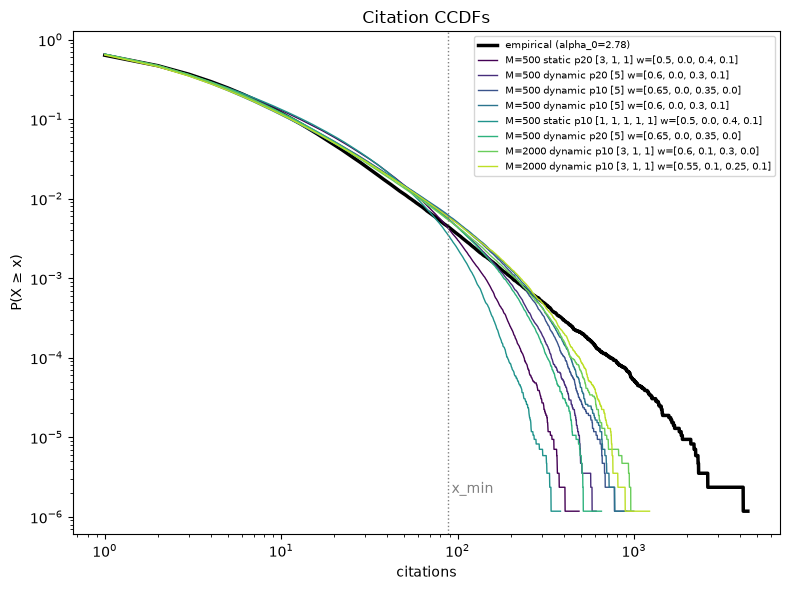

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
xs = np.arange(1, emp.max() + 1)
ax.loglog(xs, ccdf(emp, xs), color="black", lw=2.5, label=f"empirical (alpha_0={ALPHA0:.2f})")
for (m, c), color in zip([r for r in runs if r[1].seed == 0], plt.cm.viridis(np.linspace(0, 0.9, 8))):
    x = np.load(BASE / f"titles_m{m}_n850406_all_s0/runs" / c.run_id / "counts.npy")
    xs_ = np.arange(1, x.max() + 1)
    ax.loglog(xs_, ccdf(x, xs_), color=color, lw=1,
              label=f"M={m} {c.citation_signal} p{c.page_size} {list(c.per_page)} w={list(c.weights)}")
ax.axvline(XMIN, color="grey", ls=":", lw=1); ax.text(XMIN * 1.05, 2e-6, "x_min", color="grey")
ax.set_xlabel("citations"); ax.set_ylabel("P(X ≥ x)"); ax.legend(fontsize=7); ax.set_title("Citation CCDFs")
fig.tight_layout(); fig.savefig(BASE / "formal_tests_ccdf.png", dpi=150)

## 6. Conclusions

**All 24 shortlisted runs (8 settings × 3 seeds) are rejected by all four tests** (BH-adjusted q < 0.05).
The A² statistics (11–520) are far above anything the Monte Carlo null produces. The level check
(8% at a nominal 5%, from 100 replicates) is only slightly liberal, so the rejections are not marginal.
The results are identical across seeds.

* **The body matches; the tail does not.** The never-cited share (34–36% vs 36.3%) and the overall CCDF
  (maximum gap 0.014–0.020) are close. Above `x_min = 88`, though, the simulated tails are **thinner and
  curved**. Each run's own exponent is `alpha_hat` = 2.90–4.80 against `alpha_0 = 2.785`, and Vuong
  favours the **log-normal** in every run (R = −5.7 to −11). The empirical tail is a straight power law:
  it fits its own model well (A² = 0.19), and Vuong cannot separate it from a log-normal (R = −0.83, p = 0.41).
* **Closest settings:** the 2,000-result pool with dynamic counts, (0.55, 0.1, 0.25, 0.1) or
  (0.6, 0.1, 0.3, 0), page size 10, [3,1,1]. Their exponent is off by only +0.12 to +0.20, and their A²
  values are the smallest (11–16). The static-signal settings, which match the body best, have the worst
  tails (Δα = +1.4 to +2.0).
* **Interpretation.** Topical search with moderate citation-based ranking reproduces the bulk of the
  empirical distribution. Its tail bends like a log-normal because a paper can only be cited by queries
  that retrieve it (the top-M pool caps its exposure). Enlarging the pool from 500 to 2,000 moved the tail
  in the right direction, which supports this explanation. Mechanisms to test next: a larger or uncapped
  pool, or a global "highly cited" channel through which papers are found regardless of topic.